# Observatório de Londrina: Clima e Sinistros Rodoviários na BR-369 (2022–2025)

**Autores:** Caio Gabriel Duque Cotting e Victor Gomes Cardoso  
**Disciplina:** Ciência de Dados / Machine Learning — Prof. Mário Henrique Akihiko da Costa Adaniya  

Este notebook apresenta a jornada completa de **Descoberta, Qualidade, Integração (ETL), Análise Exploratória de Dados (EDA), Recortes Modais/Horários/Gênero e Machine Learning** sobre a relação entre condições meteorológicas diárias (INMET) e a frequência/severidade de sinistros de trânsito nas rodovias federais que cortam o município de Londrina-PR (PRF).

## 1. Carregamento das Bases e Inspeção de Schema

Carregamos as bases consolidadas e enriquecidas geradas pelo pipeline reprodutível em `src/etl_pipeline.py`:
* **Base diária (`1 linha = 1 dia civil em Londrina`):** 2022–2024 e 2022–2025;
* **Ocorrências individuais (`1 linha = 1 sinistro`):** microdados `datatran` filtrados para Londrina;
* **Pessoas e Veículos (`1 linha = 1 pessoa/veículo envolvido`):** microdados `acidentes*_pessoa` filtrados para Londrina;
* **Resumo horário INMET `A835`:** distribuição de horas com precipitação efetiva (> 0 mm) no período 2022–2024.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 120

BASE_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
PROCESSED_DIR = BASE_DIR / 'data' / 'processed'

daily_22_24 = pd.read_csv(PROCESSED_DIR / 'base_consolidada_londrina_diaria_2022_2024.csv', parse_dates=['data'])
daily_full = pd.read_csv(PROCESSED_DIR / 'base_consolidada_londrina_diaria_2022_2025.csv', parse_dates=['data'])
prf_22_24 = pd.read_csv(PROCESSED_DIR / 'prf_sinistros_londrina_2022_2024_enriquecido.csv', parse_dates=['data'])
prf_full = pd.read_csv(PROCESSED_DIR / 'prf_sinistros_londrina_2022_2025_enriquecido.csv', parse_dates=['data'])
pes_22_24 = pd.read_csv(PROCESSED_DIR / 'prf_pessoas_veiculos_londrina_2022_2024_enriquecido.csv', parse_dates=['data'])
pes_full = pd.read_csv(PROCESSED_DIR / 'prf_pessoas_veiculos_londrina_2022_2025_enriquecido.csv', parse_dates=['data'])
hourly_a835 = pd.read_csv(PROCESSED_DIR / 'inmet_a835_resumo_horario_2022_2024.csv')

print(f'Base Diária (2022-2024):              {daily_22_24.shape[0]} dias x {daily_22_24.shape[1]} variáveis')
print(f'Base Diária (2022-2025):              {daily_full.shape[0]} dias x {daily_full.shape[1]} variáveis')
print(f'Ocorrências PRF Londrina (2022-2024): {prf_22_24.shape[0]} sinistros')
print(f'Ocorrências PRF Londrina (2022-2025): {prf_full.shape[0]} sinistros')
print(f'Pessoas/Veículos (2022-2024):         {pes_22_24.shape[0]} registros')
print(f'Pessoas/Veículos (2022-2025):         {pes_full.shape[0]} registros')
display(daily_22_24[['data', 'total_acidentes', 'acidentes_com_vitimas', 'acidentes_fatais', 'temp_media_c', 'precip_londrina_mm', 'cenario_chuva_londrina']].head())

Base Diária (2022-2024):              1096 dias x 59 variáveis
Base Diária (2022-2025):              1461 dias x 59 variáveis
Ocorrências PRF Londrina (2022-2024): 509 sinistros
Ocorrências PRF Londrina (2022-2025): 692 sinistros
Pessoas/Veículos (2022-2024):         1265 registros
Pessoas/Veículos (2022-2025):         1721 registros


,data,total_acidentes,acidentes_com_vitimas,acidentes_fatais,temp_media_c,precip_londrina_mm,cenario_chuva_londrina
0,2022-01-01,0,0,0,24.7,1.6,Chuvoso (>= 1 mm)
1,2022-01-02,0,0,0,26.0,0.1,Seco (< 1 mm)
2,2022-01-03,0,0,0,25.6,13.3,Chuvoso (>= 1 mm)
3,2022-01-04,0,0,0,23.8,5.1,Chuvoso (>= 1 mm)
4,2022-01-05,1,1,0,24.6,5.0,Chuvoso (>= 1 mm)


### Análise do Schema e Granularidade

A base consolidada no recorte oficial do projeto (2022–2024) preserva exatamente **1.096 observações diárias** ($365 + 365 + 366\text{ dias}$, contemplando o ano bissexto de 2024), sem qualquer descarte de dias com contagem zero. Entre 2022 e 2024, foram registrados **509 sinistros** (média de $0{,}464\text{ sinistros/dia}$) envolvendo **1.265 registros de pessoas/veículos**; com a extensão de 2025 ($1.461\text{ dias}$), a série alcança **692 sinistros** e **1.721 registros de envolvidos**.

## 2. Auditoria de Qualidade dos Dados e Valores Ausentes (NULLs)

Antes das inferências estatísticas e da modelagem preditiva, verificamos a frequência de valores ausentes (`NULL`/`NaN`) e a distribuição de rodovias federais no recorte de Londrina.

In [2]:
null_report = pd.DataFrame({
    'Nulos (2022-2024)': daily_22_24.isna().sum(),
    '% Nulos (2022-2024)': (daily_22_24.isna().mean() * 100).round(2),
    'Nulos (2022-2025)': daily_full.isna().sum(),
    '% Nulos (2022-2025)': (daily_full.isna().mean() * 100).round(2),
})
print('Variáveis com valores ausentes na base diária:')
display(null_report[null_report['Nulos (2022-2025)'] > 0])

print('\nDistribuição das rodovias (BR) nos registros de Londrina (2022-2025):')
print(prf_full['br'].value_counts())

Variáveis com valores ausentes na base diária:


,Nulos (2022-2024),% Nulos (2022-2024),Nulos (2022-2025),% Nulos (2022-2025)
inmet_83766_precip_mm,159,14.51,175,11.98
sblo_83768_precip_mm,155,14.14,171,11.70
a835_precip_mm,9,0.82,333,22.79
a835_temp_media_c,9,0.82,333,22.79
a835_temp_max_c,9,0.82,333,22.79
a835_temp_min_c,9,0.82,333,22.79
a835_umid_media_pct,9,0.82,333,22.79
a835_vento_max_ms,9,0.82,333,22.79
dia_chuvoso_a835,9,0.82,333,22.79
taxa_severidade_vitimas_pct,676,61.68,901,61.67



Distribuição das rodovias (BR) nos registros de Londrina (2022-2025):
br
369    686
0        4
376      2
Name: count, dtype: int64


### Diagnóstico de Valores Ausentes e Validade

1. **Taxas diárias condicionais (`taxa_severidade_*`, `taxa_letalidade_pct`):** Apresentam `NaN` nos dias em que não houve nenhum acidente ($61{,}7\%$ em 2022–2024), pois $0/0$ é matematicamente indefinido e não deve ser confundido com $0\%$ de severidade.
2. **Descoberta sobre as Estações do INMET (`83766` Londrina vs. `A835` Maringá):** Nos arquivos `.zip` de estações automáticas do INMET, `A835` refere-se a **Maringá-PR** (que tem excelente cobertura em 2022–2024, mas interrompe registros após fevereiro de 2025). Já a estação oficial do INMET dentro de **Londrina (`83766`)** tem **$0\%$ de nulos em temperatura** nos 4 anos e teve lacunas pluviométricas de 2022 preenchidas hierarquicamente por `SBLO 83768` e `ERA5`, zerando nulos em `temp_media_c` e `precip_londrina_mm`.
3. **Registros com `br = 0`:** As 4 ocorrências com `br = 0` (1 em 2022 e 3 em 2025) possuem coordenadas válidas em alças urbanas da BR-369.

## 3. Análise das 4 Perguntas Secundárias do Project Canvas (2022–2024)

Avaliamos quantitativa e visualmente cada uma das quatro perguntas secundárias definidas na Atividade 1.

In [3]:
# P1: Média diária em dias chuvosos (>= 1 mm) vs dias secos (< 1 mm)
p1_table = daily_22_24.groupby('cenario_chuva_londrina').agg(
    dias=('data', 'count'),
    total_acidentes=('total_acidentes', 'sum'),
    media_diaria=('total_acidentes', 'mean'),
    desvio_padrao=('total_acidentes', 'std'),
    pct_dias_com_acidente=('total_acidentes', lambda s: (s > 0).mean() * 100),
).round(3)
chuv_s = daily_22_24[daily_22_24['dia_chuvoso_londrina'] == 1]['total_acidentes']
seco_s = daily_22_24[daily_22_24['dia_chuvoso_londrina'] == 0]['total_acidentes']
_, p_welch = stats.ttest_ind(chuv_s, seco_s, equal_var=False)
_, p_mw = stats.mannwhitneyu(chuv_s, seco_s, alternative='two-sided')
print(f'=== PERGUNTA 1: Dias Chuvosos vs. Secos (Welch p={p_welch:.4f} | Mann-Whitney p={p_mw:.4f}) ===')
display(p1_table)

# P2: Média diária por faixa de temperatura média
p2_table = daily_22_24.groupby('faixa_temperatura_media', observed=False).agg(
    dias=('data', 'count'),
    total_acidentes=('total_acidentes', 'sum'),
    media_diaria=('total_acidentes', 'mean'),
    pct_dias_com_acidente=('total_acidentes', lambda s: (s > 0).mean() * 100),
).round(3)
print('=== PERGUNTA 2: Faixas de Temperatura Média Diária (2022-2024) ===')
display(p2_table)

# P3: Severidade e Letalidade por ocorrência (Condição na PRF)
p3_table = prf_22_24.groupby('condicao_chuva_prf').agg(
    ocorrencias=('id', 'count'),
    taxa_com_vitimas_pct=('tem_vitima', lambda s: s.mean() * 100),
    taxa_graves_ou_fatais_pct=('tem_grave_ou_morte', lambda s: s.mean() * 100),
    obitos=('mortos', 'sum'),
    taxa_letalidade_pct=('tem_obito', lambda s: s.mean() * 100),
).round(2)
p3_table.index = ['Sem Chuva na PRF (Céu Claro/Sol/Nublado)', 'Com Chuva/Garoa na PRF']
print('=== PERGUNTA 3: Severidade e Letalidade por Ocorrência (2022-2024) ===')
display(p3_table)

# P4: Índice de concordância entre Chuva na PRF e Estações Meteorológicas
chuva_prf = prf_22_24[prf_22_24['condicao_chuva_prf'] == 1]
print('=== PERGUNTA 4: Índice de Concordância (PRF vs. INMET) ===')
print(f'Ocorrências com Chuva/Garoa na PRF: {len(chuva_prf)}/{len(prf_22_24)} ({len(chuva_prf)/len(prf_22_24)*100:.1f}%)')
print(f'Concordância com chuva > 0 mm em Londrina:  {(chuva_prf["precip_londrina_mm"] > 0).mean()*100:.1f}%')
print(f'Concordância com chuva >= 1 mm em Londrina: {(chuva_prf["precip_londrina_mm"] >= 1.0).mean()*100:.1f}%')
print(f'Concordância com chuva >= 1 mm em A835:     {(chuva_prf["a835_precip_mm"].dropna() >= 1.0).mean()*100:.1f}%')

=== PERGUNTA 1: Dias Chuvosos vs. Secos (Welch p=0.1675 | Mann-Whitney p=0.4043) ===


,dias,total_acidentes,media_diaria,desvio_padrao,pct_dias_com_acidente
cenario_chuva_londrina,,,,,
Chuvoso (>= 1 mm),416,179,0.430,0.605,37.260
Seco (< 1 mm),680,330,0.485,0.693,38.971


=== PERGUNTA 2: Faixas de Temperatura Média Diária (2022-2024) ===


,dias,total_acidentes,media_diaria,pct_dias_com_acidente
faixa_temperatura_media,,,,
Ameno (19-24°C),497,226,0.455,37.827
Frio (<= 19°C),201,106,0.527,40.796
Quente (> 24°C),398,177,0.445,37.688


=== PERGUNTA 3: Severidade e Letalidade por Ocorrência (2022-2024) ===


,ocorrencias,taxa_com_vitimas_pct,taxa_graves_ou_fatais_pct,obitos,taxa_letalidade_pct
Sem Chuva na PRF (Céu Claro/Sol/Nublado),468,83.12,25.21,15,3.21
Com Chuva/Garoa na PRF,41,82.93,31.71,0,0.00


=== PERGUNTA 4: Índice de Concordância (PRF vs. INMET) ===
Ocorrências com Chuva/Garoa na PRF: 41/509 (8.1%)
Concordância com chuva > 0 mm em Londrina:  100.0%
Concordância com chuva >= 1 mm em Londrina: 95.1%
Concordância com chuva >= 1 mm em A835:     82.9%


### Interpretação Estatística das 4 Perguntas Secundárias

* **Pergunta 1 (Frequência Diária Chuvoso vs. Seco):** Dias secos ($< 1\text{ mm}$) apresentaram média de **$0{,}485\text{ acidentes/dia}$** contra **$0{,}430\text{ acidentes/dia}$** em dias chuvosos ($\ge 1\text{ mm}$, Welch $p = 0{,}1675$). Como veremos na Seção 4, esse aparente paradoxo decorre tanto da concentração temporal da chuva em poucas horas do dia quanto da redução de exposição de motos e pedestres.
* **Pergunta 2 (Faixas Térmicas):** Os **dias frios ($\le 19^\circ\text{C}$)** registram a maior média diária (**$0{,}527\text{ sinistros/dia}$**, com $40{,}8\%$ dos dias tendo sinistros), superando dias amenos ($0{,}455/\text{dia}$) e quentes ($0{,}445/\text{dia}$).
* **Pergunta 3 (Severidade e Letalidade — Confirmação da Hipótese):** Nos **41 sinistros sob chuva/garoa** em 2022–2024, a **taxa de letalidade foi $0{,}00\%$ (zero óbitos)** contra **$3{,}21\%$ ($15\text{ óbitos}$)** em tempo seco/nublado. No agregado diário ($\ge 1\text{ mm}$), a letalidade cai de $3{,}64\%$ para $1{,}68\%$, corroborando a hipótese de redução preventiva de velocidade.
* **Pergunta 4 (Concordância PRF vs. INMET):** Há **$100{,}0\%$ de concordância** entre o boletim de chuva/garoa da PRF e precipitação $> 0\text{ mm}$ na série local de Londrina ($95{,}1\%$ em dias $\ge 1\text{ mm}$).

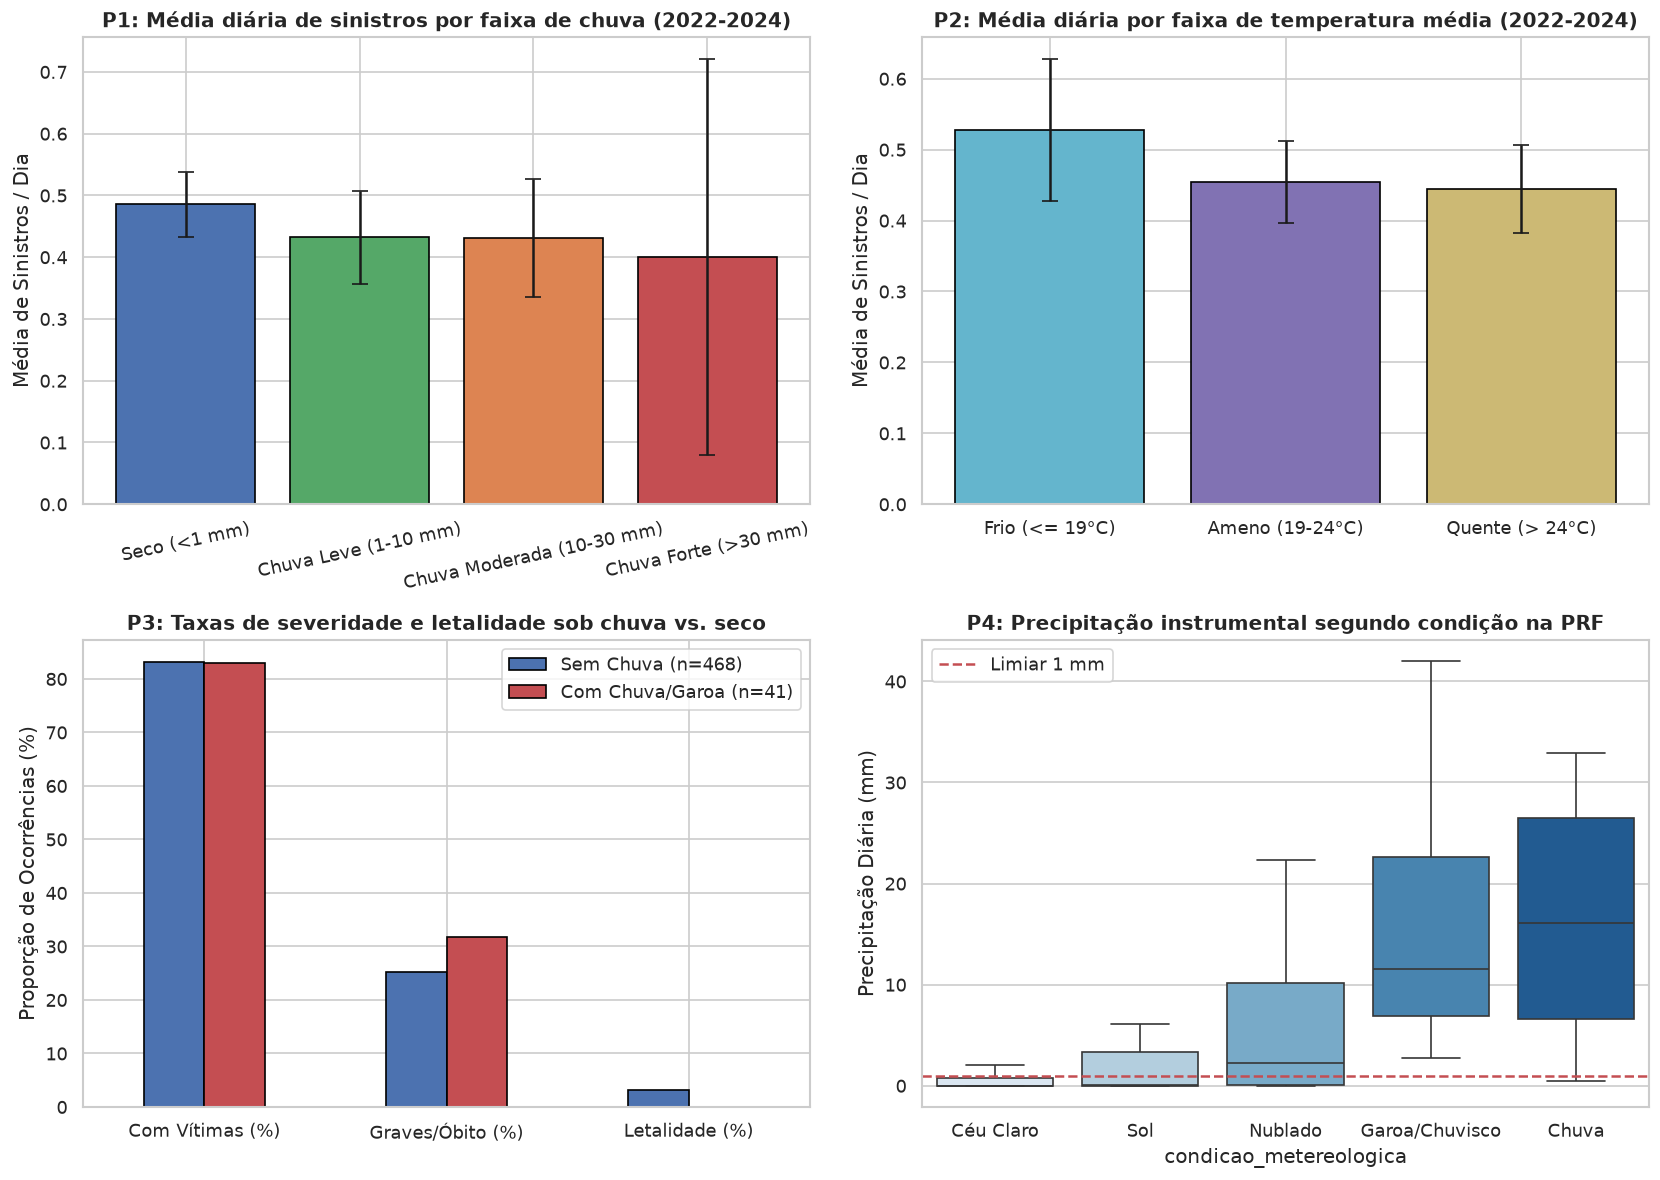

In [4]:
# Painel visual das 4 Perguntas Secundárias do Project Canvas
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

ordem_p = ['Seco (<1 mm)', 'Chuva Leve (1-10 mm)', 'Chuva Moderada (10-30 mm)', 'Chuva Forte (>30 mm)']
grp_p = daily_22_24.groupby('faixa_precipitacao', observed=False)['total_acidentes'].agg(['mean', 'count', 'std']).reindex(ordem_p).reset_index()
grp_p['se'] = grp_p['std'] / np.sqrt(grp_p['count'])
axes[0, 0].bar(grp_p['faixa_precipitacao'].astype(str), grp_p['mean'], yerr=1.96*grp_p['se'], capsize=5, color=['#4C72B0', '#55A868', '#DD8452', '#C44E52'], edgecolor='black')
axes[0, 0].set_title('P1: Média diária de sinistros por faixa de chuva (2022-2024)', fontweight='bold')
axes[0, 0].set_ylabel('Média de Sinistros / Dia')
axes[0, 0].tick_params(axis='x', rotation=12)

ordem_t = ['Frio (<= 19°C)', 'Ameno (19-24°C)', 'Quente (> 24°C)']
grp_t = daily_22_24.groupby('faixa_temperatura_media', observed=False)['total_acidentes'].agg(['mean', 'count', 'std']).reindex(ordem_t).reset_index()
grp_t['se'] = grp_t['std'] / np.sqrt(grp_t['count'])
axes[0, 1].bar(grp_t['faixa_temperatura_media'].astype(str), grp_t['mean'], yerr=1.96*grp_t['se'], capsize=5, color=['#64B5CD', '#8172B3', '#CCB974'], edgecolor='black')
axes[0, 1].set_title('P2: Média diária por faixa de temperatura média (2022-2024)', fontweight='bold')
axes[0, 1].set_ylabel('Média de Sinistros / Dia')

sev_df = prf_22_24.groupby('condicao_chuva_prf').agg(
    vitimas=('tem_vitima', lambda s: s.mean()*100),
    graves=('tem_grave_ou_morte', lambda s: s.mean()*100),
    obitos=('tem_obito', lambda s: s.mean()*100)
).T
sev_df.columns = ['Sem Chuva (n=468)', 'Com Chuva/Garoa (n=41)']
sev_df.index = ['Com Vítimas (%)', 'Graves/Óbito (%)', 'Letalidade (%)']
sev_df.plot(kind='bar', ax=axes[1, 0], color=['#4C72B0', '#C44E52'], edgecolor='black', rot=0)
axes[1, 0].set_title('P3: Taxas de severidade e letalidade sob chuva vs. seco', fontweight='bold')
axes[1, 0].set_ylabel('Proporção de Ocorrências (%)')

cond_order = ['Céu Claro', 'Sol', 'Nublado', 'Garoa/Chuvisco', 'Chuva']
sub_cond = prf_22_24[prf_22_24['condicao_metereologica'].isin(cond_order)]
sns.boxplot(data=sub_cond, x='condicao_metereologica', y='precip_londrina_mm', hue='condicao_metereologica', order=cond_order, hue_order=cond_order, palette='Blues', legend=False, ax=axes[1, 1], showfliers=False)
axes[1, 1].axhline(1.0, color='#C44E52', linestyle='--', label='Limiar 1 mm')
axes[1, 1].set_title('P4: Precipitação instrumental segundo condição na PRF', fontweight='bold')
axes[1, 1].set_ylabel('Precipitação Diária (mm)')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

### Análise Visual do Painel do Project Canvas

Os gráficos confirmam visualmente: (1) intervalos de confiança sobrepostos entre faixas de precipitação; (2) maior média nos dias frios ($\le 19^\circ\text{C}$); (3) queda da letalidade para **$0{,}0\%$** sob chuva/garoa apesar de leve alta em feridos graves ($31{,}7\%$ vs. $25{,}2\%$); e (4) forte separação na precipitação instrumental quando o policial relata `'Garoa/Chuvisco'` ou `'Chuva'`.

## 4. Análise Modal (Tipo de Transporte), Exposição Horária (00h–23h) e Proporções

Investigamos três aprofundamentos essenciais sobre o comportamento real da BR-369 em Londrina:
1. **Resolução do Paradoxo do Dia Chuvoso:** Quantas horas do ano realmente têm precipitação efetiva no registro horário do INMET (`A835`, 2022–2024)?
2. **Variação por Tipo de Transporte:** Como reagem carros, motos, caminhões, pedestres, ônibus e bicicletas quando comparados dias secos vs. chuvosos (em taxa ajustada por 100 dias)?
3. **Proporções por Dia da Semana e Mapa Horário (00h–23h):** Qual é a combinação crítica de dia, clima e hora do dia para cada modal?

In [5]:
# 1. Fração horária real de chuva no INMET A835 (2022-2024)
h_valid = int(hourly_a835['horas_validas'].sum())
h_rain = int(hourly_a835['horas_com_chuva'].sum())
print(f'Horas com chuva efetiva (>0 mm) no INMET A835 (2022-2024): {h_rain}/{h_valid} horas ({h_rain/h_valid*100:.2f}% do tempo)')

# 2. Proporção semanal ajustada por dias secos vs dias chuvosos
ordem_dias = ['segunda-feira', 'terça-feira', 'quarta-feira', 'quinta-feira', 'sexta-feira', 'sábado', 'domingo']
dow_rows = []
for dia in ordem_dias:
    ds = daily_22_24[(daily_22_24['dia_semana'] == dia) & (daily_22_24['dia_chuvoso_londrina'] == 0)]
    dc = daily_22_24[(daily_22_24['dia_semana'] == dia) & (daily_22_24['dia_chuvoso_londrina'] == 1)]
    tx_s = ds['total_acidentes'].mean() * 100
    tx_c = dc['total_acidentes'].mean() * 100
    dow_rows.append({
        'Dia_Semana': dia,
        'Dias_Secos': len(ds), 'Acid_Secos': int(ds['total_acidentes'].sum()), 'Taxa_Seco_100d': round(tx_s, 1),
        'Dias_Chuv': len(dc), 'Acid_Chuv': int(dc['total_acidentes'].sum()), 'Taxa_Chuv_100d': round(tx_c, 1),
        'Var_Chuva_%': round((tx_c / tx_s - 1) * 100, 1)
    })
dow_df = pd.DataFrame(dow_rows)
print('\n=== PROPORÇÃO POR DIA DA SEMANA x CLIMA (2022-2024) ===')
display(dow_df)

# 3. Variação por Tipo de Transporte (2022-2024 e 2022-2025)
n_seco_24 = int((daily_22_24['dia_chuvoso_londrina'] == 0).sum())
n_chuv_24 = int((daily_22_24['dia_chuvoso_londrina'] == 1).sum())
acc_mod_24 = pes_22_24[pes_22_24['modal'] != 'Outros'].drop_duplicates(subset=['id', 'modal']).copy()
t_mod_24 = acc_mod_24.groupby(['modal', 'dia_chuvoso_londrina'])['id'].nunique().unstack(fill_value=0)
t_mod_24.columns = ['Acid_Seco', 'Acid_Chuvoso']
t_mod_24['Total'] = t_mod_24['Acid_Seco'] + t_mod_24['Acid_Chuvoso']
t_mod_24['Taxa_100d_Seco'] = (t_mod_24['Acid_Seco'] / n_seco_24 * 100).round(2)
t_mod_24['Taxa_100d_Chuv'] = (t_mod_24['Acid_Chuvoso'] / n_chuv_24 * 100).round(2)
t_mod_24['Var_Chuva_%'] = ((t_mod_24['Taxa_100d_Chuv'] / t_mod_24['Taxa_100d_Seco'] - 1) * 100).round(1)
print('=== VARIAÇÃO POR TIPO DE TRANSPORTE (2022-2024: 680 dias secos vs 416 chuvosos) ===')
display(t_mod_24.sort_values('Total', ascending=False))

# 4. Campeões de dia e horário por modal
peaks = []
for m in ['Carro', 'Moto', 'Caminhão', 'Pedestre', 'Ônibus', 'Bicicleta']:
    sm = acc_mod_24[acc_mod_24['modal'] == m]
    dh = sm.groupby(['dia_semana', 'hora'])['id'].nunique()
    best_dh = dh.idxmax()
    peaks.append({
        'Modal': m,
        'Ocorrências': sm['id'].nunique(),
        'Dia_Pico': sm.groupby('dia_semana')['id'].nunique().idxmax(),
        'Hora_Pico': f"{sm.groupby('hora')['id'].nunique().idxmax():02d}h",
        'Combinação_Líder': f"{best_dh[0]} às {best_dh[1]:02d}h ({dh.max()}x)"
    })
print('=== PICOS TEMPORAIS POR MODAL (2022-2024) ===')
display(pd.DataFrame(peaks))

Horas com chuva efetiva (>0 mm) no INMET A835 (2022-2024): 1786/25767 horas (6.93% do tempo)

=== PROPORÇÃO POR DIA DA SEMANA x CLIMA (2022-2024) ===


,Dia_Semana,Dias_Secos,Acid_Secos,Taxa_Seco_100d,Dias_Chuv,Acid_Chuv,Taxa_Chuv_100d,Var_Chuva_%
0,segunda-feira,96,40,41.7,61,22,36.1,-13.4
1,terça-feira,93,47,50.5,64,29,45.3,-10.3
2,quarta-feira,90,53,58.9,66,27,40.9,-30.5
3,quinta-feira,97,39,40.2,59,22,37.3,-7.3
4,sexta-feira,94,65,69.1,62,33,53.2,-23.0
5,sábado,106,50,47.2,51,28,54.9,16.4
6,domingo,104,36,34.6,53,18,34.0,-1.9


=== VARIAÇÃO POR TIPO DE TRANSPORTE (2022-2024: 680 dias secos vs 416 chuvosos) ===


,Acid_Seco,Acid_Chuvoso,Total,Taxa_100d_Seco,Taxa_100d_Chuv,Var_Chuva_%
modal,,,,,,
Carro,238,128,366,35.00,30.77,-12.1
Moto,203,100,303,29.85,24.04,-19.5
Caminhão,50,36,86,7.35,8.65,17.7
Pedestre,24,11,35,3.53,2.64,-25.2
Ônibus,11,4,15,1.62,0.96,-40.7
Bicicleta,8,3,11,1.18,0.72,-39.0


=== PICOS TEMPORAIS POR MODAL (2022-2024) ===


,Modal,Ocorrências,Dia_Pico,Hora_Pico,Combinação_Líder
0,Carro,366,sábado,17h,quarta-feira às 18h (9x)
1,Moto,303,sexta-feira,18h,quarta-feira às 18h (12x)
2,Caminhão,86,sexta-feira,08h,sexta-feira às 12h (4x)
3,Pedestre,35,terça-feira,20h,domingo às 20h (2x)
4,Ônibus,15,quinta-feira,06h,domingo às 06h (1x)
5,Bicicleta,11,quarta-feira,07h,sexta-feira às 18h (2x)


### Interpretação Modal, Horária e do Paradoxo da Chuva

1. **Por que a média do dia chuvoso é menor na contagem bruta (`0,430` vs `0,485`)?**
   * Apenas **$6{,}93\%$ das horas** medidas no INMET (`1.786` de `25.767` horas em 2022–2024) têm precipitação efetiva ($> 0\text{ mm}$), e somente **$21{,}8\%$ dos sinistros** em dias chuvosos ocorreram exatamente debaixo de chuva/garoa.
   * Quando chove o dia inteiro, motos (**$-19{,}5\%$** por 100 dias), pedestres (**$-25{,}2\%$**), bicicletas (**$-39{,}0\%$**) e ônibus (**$-40{,}7\%$**) reduzem drasticamente sua exposição na rodovia.
2. **O contraste dos Caminhões e dos Sábados Chuvosos:**
   * **Caminhões/carretas são o único modal que sobe na chuva** (**$+17{,}7\%$** em 2022–2024; **$+27{,}0\%$** na série estendida 2022–2025), pois o transporte rodoviário de cargas não cancela viagens pela chuva e sofre mais com perda de atrito e distância de frenagem em pista molhada.
   * **Aos sábados**, quando o trânsito de lazer/serviços se soma à pista molhada, a taxa de sinistros em dias chuvosos (**$54{,}9/100\text{d}$**) supera a de sábados secos (**$47{,}2/100\text{d}$**, **$+16{,}4\%$**).

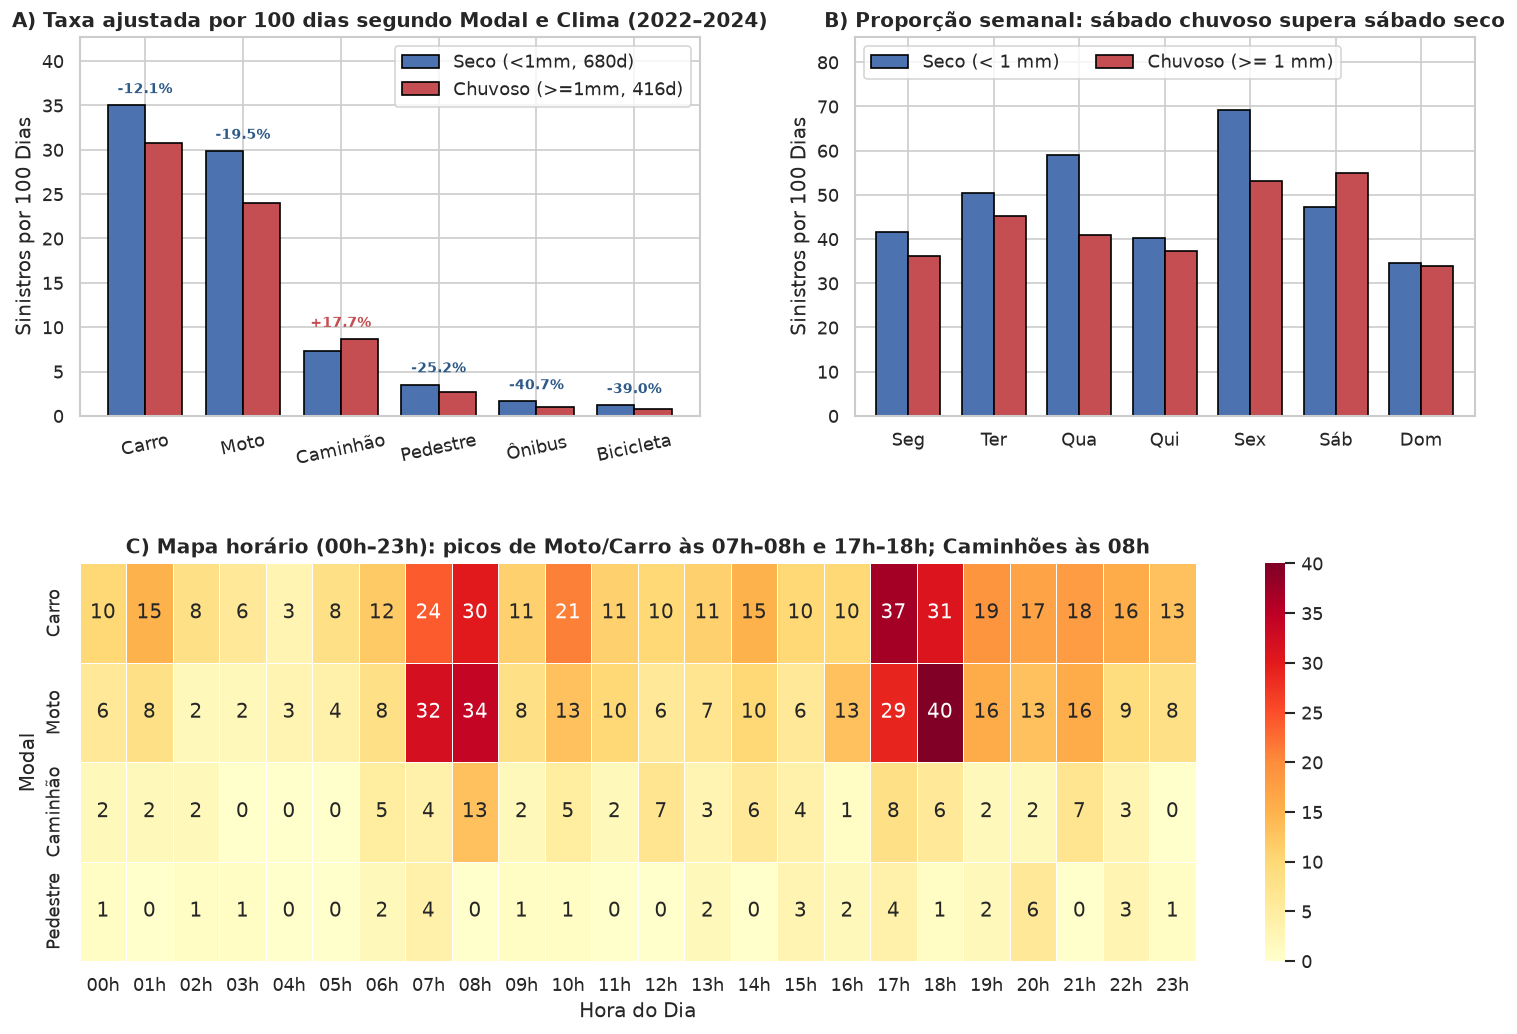

In [6]:
# Painel visual: Modais x Clima, Proporção Semanal e Heatmap Horário (00h-23h)
fig = plt.figure(figsize=(15, 10))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.05], hspace=0.38, wspace=0.25)

t_plot = t_mod_24.sort_values('Taxa_100d_Seco', ascending=False)
ax_a = fig.add_subplot(gs[0, 0])
x = np.arange(len(t_plot))
w = 0.38
b1 = ax_a.bar(x - w/2, t_plot['Taxa_100d_Seco'], w, label=f'Seco (<1mm, {n_seco_24}d)', color='#4C72B0', edgecolor='black')
b2 = ax_a.bar(x + w/2, t_plot['Taxa_100d_Chuv'], w, label=f'Chuvoso (>=1mm, {n_chuv_24}d)', color='#C44E52', edgecolor='black')
for i, (bs, bc, v) in enumerate(zip(b1, b2, t_plot['Var_Chuva_%'])):
    ax_a.text(i, max(bs.get_height(), bc.get_height()) + 1.0, f'{v:+.1f}%', ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#C44E52' if v > 0 else '#2E5A88')
ax_a.set_xticks(x)
ax_a.set_xticklabels(t_plot.index, rotation=12)
ax_a.set_ylabel('Sinistros por 100 Dias')
ax_a.set_ylim(0, t_plot[['Taxa_100d_Seco', 'Taxa_100d_Chuv']].values.max() * 1.22)
ax_a.set_title('A) Taxa ajustada por 100 dias segundo Modal e Clima (2022–2024)', fontweight='bold')
ax_a.legend()

ax_b = fig.add_subplot(gs[0, 1])
dow_plot = dow_df.set_index('Dia_Semana')[['Taxa_Seco_100d', 'Taxa_Chuv_100d']]
dow_plot.columns = ['Seco (< 1 mm)', 'Chuvoso (>= 1 mm)']
dow_plot.plot(kind='bar', ax=ax_b, color=['#4C72B0', '#C44E52'], edgecolor='black', width=0.75)
ax_b.set_title('B) Proporção semanal: sábado chuvoso supera sábado seco', fontweight='bold')
ax_b.set_xlabel('')
ax_b.set_ylabel('Sinistros por 100 Dias')
ax_b.set_ylim(0, dow_plot.values.max() * 1.24)
ax_b.set_xticklabels([d[:3].capitalize() for d in ordem_dias], rotation=0)
ax_b.legend(ncol=2, loc='upper left')

ax_c = fig.add_subplot(gs[1, :])
h_mod = acc_mod_24[acc_mod_24['modal'].isin(['Carro', 'Moto', 'Caminhão', 'Pedestre'])].pivot_table(
    index='hora', columns='modal', values='id', aggfunc='nunique', fill_value=0
).reindex(range(24), fill_value=0)
sns.heatmap(h_mod[['Carro', 'Moto', 'Caminhão', 'Pedestre']].T, annot=True, fmt='d', cmap='YlOrRd', linewidths=0.4, ax=ax_c)
ax_c.set_title('C) Mapa horário (00h–23h): picos de Moto/Carro às 07h–08h e 17h–18h; Caminhões às 08h', fontweight='bold')
ax_c.set_xlabel('Hora do Dia')
ax_c.set_ylabel('Modal')
ax_c.set_xticklabels([f'{h:02d}h' for h in range(24)], rotation=0)
plt.show()

### Análise Visual do Comportamento Modal e Horário

O painel evidencia a dupla dinâmica horária da BR-369 em Londrina: **picos de deslocamento pendular às `07h–08h` e `17h–18h`** (com forte concentração de motocicletas e automóveis) e **pico matinal de caminhões às `08h`** ($13$ sinistros entre 2022–2024; $17$ em 2022–2025). Já os atropelamentos de pedestres ocorrem com mais frequência ao anoitecer (`20h`).

## 5. Recorte por Gênero (`Condutor`, `Passageiro` e `Pedestre`)

Utilizando a tabela de envolvidos (`prf_pessoas_veiculos_londrina_2022_2024_enriquecido.csv`), avaliamos a participação, o perfil veicular, a variação sob chuva e a gravidade por gênero.

=== 1. ENVOLVIDOS POR GÊNERO x PAPEL (2022-2024) ===


tipo_envolvido_clean,Condutor,Passageiro,Pedestre,Testemunha,Total,%_Total
genero,,,,,,
Feminino,138,116,12,0,266,21.0
Masculino,754,77,26,0,857,67.7
Não Informado / Ignorado,61,0,0,42,103,8.1


=== 2. CONDUTORES POR GÊNERO x CLIMA (2022-2024) ===


,Seco,Chuvoso,Taxa_100d_Seco,Taxa_100d_Chuv,Var_Chuva_%
genero,,,,,
Feminino,93,45,13.68,10.82,-20.9
Masculino,496,258,72.94,62.02,-15.0


Composição por sinistro (n=491): Apenas Homens=368 (74.9%) | Apenas Mulheres=33 (6.7%) | Misto=90 (18.3%)


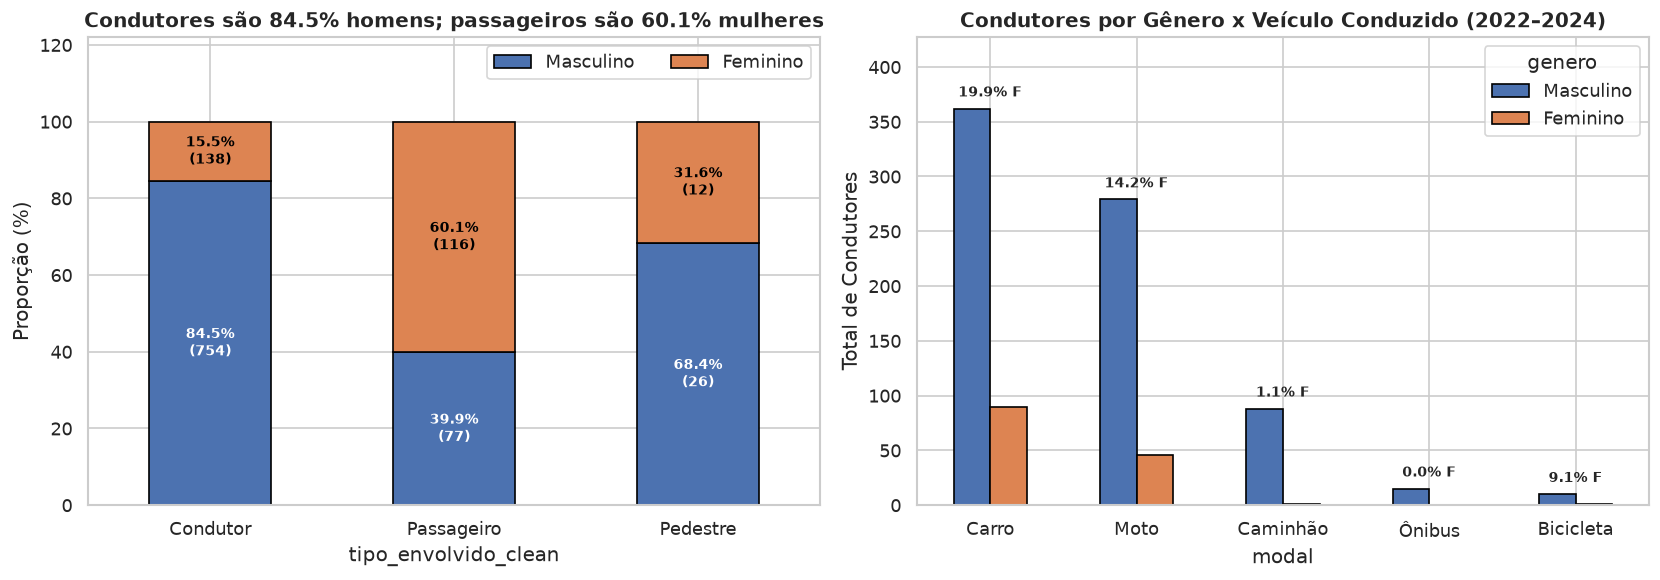

In [7]:
t_env = pes_22_24.groupby(['genero', 'tipo_envolvido_clean'])['pesid'].count().unstack(fill_value=0)
t_env['Total'] = t_env.sum(axis=1)
t_env['%_Total'] = (t_env['Total'] / len(pes_22_24) * 100).round(1)
print('=== 1. ENVOLVIDOS POR GÊNERO x PAPEL (2022-2024) ===')
display(t_env)

cond_24 = pes_22_24[(pes_22_24['tipo_envolvido_clean'] == 'Condutor') & (pes_22_24['genero'].isin(['Masculino', 'Feminino']))].copy()
t_g_cl = cond_24.groupby(['genero', 'dia_chuvoso_londrina'])['pesid'].count().unstack(fill_value=0)
t_g_cl.columns = ['Seco', 'Chuvoso']
t_g_cl['Taxa_100d_Seco'] = (t_g_cl['Seco'] / n_seco_24 * 100).round(2)
t_g_cl['Taxa_100d_Chuv'] = (t_g_cl['Chuvoso'] / n_chuv_24 * 100).round(2)
t_g_cl['Var_Chuva_%'] = ((t_g_cl['Taxa_100d_Chuv'] / t_g_cl['Taxa_100d_Seco'] - 1) * 100).round(1)
print('=== 2. CONDUTORES POR GÊNERO x CLIMA (2022-2024) ===')
display(t_g_cl)

by_id_g = cond_24.groupby('id')['genero'].apply(set)
n_ids = len(by_id_g)
print(f'Composição por sinistro (n={n_ids}): Apenas Homens={sum(s=={"Masculino"} for s in by_id_g)} ({sum(s=={"Masculino"} for s in by_id_g)/n_ids*100:.1f}%) | Apenas Mulheres={sum(s=={"Feminino"} for s in by_id_g)} ({sum(s=={"Feminino"} for s in by_id_g)/n_ids*100:.1f}%) | Misto={sum(s=={"Masculino","Feminino"} for s in by_id_g)} ({sum(s=={"Masculino","Feminino"} for s in by_id_g)/n_ids*100:.1f}%)')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
env_order = ['Condutor', 'Passageiro', 'Pedestre']
env_g = pes_22_24[(pes_22_24['tipo_envolvido_clean'].isin(env_order)) & (pes_22_24['genero'].isin(['Masculino', 'Feminino']))].groupby(['tipo_envolvido_clean', 'genero'])['pesid'].count().unstack(fill_value=0).reindex(env_order)
env_pct = env_g.div(env_g.sum(axis=1), axis=0) * 100.0
env_pct[['Masculino', 'Feminino']].plot(kind='bar', stacked=True, ax=axes[0], color=['#4C72B0', '#DD8452'], edgecolor='black')
for i, r in enumerate(env_order):
    m_p, f_p = env_pct.loc[r, 'Masculino'], env_pct.loc[r, 'Feminino']
    axes[0].text(i, m_p/2, f'{m_p:.1f}%\n({env_g.loc[r, "Masculino"]})', ha='center', va='center', color='white', fontweight='bold', fontsize=8.5)
    axes[0].text(i, m_p + f_p/2, f'{f_p:.1f}%\n({env_g.loc[r, "Feminino"]})', ha='center', va='center', color='black', fontweight='bold', fontsize=8.5)
axes[0].set_ylim(0, 122)
axes[0].set_xticklabels(env_order, rotation=0)
axes[0].set_ylabel('Proporção (%)')
axes[0].set_title(f'Condutores são {env_pct.loc["Condutor", "Masculino"]:.1f}% homens; passageiros são {env_pct.loc["Passageiro", "Feminino"]:.1f}% mulheres', fontweight='bold')
axes[0].legend(ncol=2, loc='upper right')

mod_order = ['Carro', 'Moto', 'Caminhão', 'Ônibus', 'Bicicleta']
mod_g = cond_24[cond_24['modal'].isin(mod_order)].groupby(['modal', 'genero'])['pesid'].count().unstack(fill_value=0).reindex(mod_order)
mod_g[['Masculino', 'Feminino']].plot(kind='bar', ax=axes[1], color=['#4C72B0', '#DD8452'], edgecolor='black')
for i, m in enumerate(mod_order):
    tot = mod_g.loc[m].sum()
    axes[1].text(i, mod_g.loc[m].max() + 8, f'{mod_g.loc[m, "Feminino"]/tot*100:.1f}% F', ha='center', va='bottom', fontsize=8.5, fontweight='bold')
axes[1].set_ylim(0, mod_g.values.max() * 1.18)
axes[1].set_xticklabels(mod_order, rotation=0)
axes[1].set_ylabel('Total de Condutores')
axes[1].set_title('Condutores por Gênero x Veículo Conduzido (2022–2024)', fontweight='bold')
plt.tight_layout()
plt.show()

### Análise do Recorte por Gênero

Os dados mostram uma clara **divisão de papéis viários (e não apenas de risco isolado)**: entre condutores com sexo informado em 2022–2024, **$84{,}5\%$ ($754$)** são homens e **$15{,}5\%$ ($138$)** são mulheres (em veículos pesados como caminhões e ônibus, a participação masculina passa de $98\%$), enquanto entre passageiros as mulheres representam **$60{,}1\%$ ($116$ vs. $77$)**. Sob chuva, a taxa diária de envolvidas mulheres ao volante recua mais (**$-20{,}9\%$** vs. **$-15{,}0\%$** nos homens em 2022–2024; na série de 4 anos até 2025, **$-20{,}4\%$** vs. **$-8{,}9\%$**). Nota metodológica importante: não possuímos denominador de CNH ativa ou fluxo por sexo na BR-369, portanto os números medem **presença absoluta nos sinistros**, não risco individual por km rodado.

## 6. Machine Learning: Clusterização e Classificação com Divisão Cronológica Estrita

Seguindo boas práticas rigorosas de Machine Learning para séries temporais:
1. **Divisão Cronológica Estrita ANTES do Pré-processamento:** Separamos `Treino (2022–2023)`, `Validação (2024)` e `Teste (2025)` antes de ajustar `SimpleImputer`, `StandardScaler` e `OneHotEncoder`, prevenindo *data leakage*.
2. **Comparação com Baselines e Intervalos de Confiança via Bootstrap (95%):** Avaliamos *Naive Baseline*, *Logistic Regression (L2)*, *Random Forest* e *Gradient Boosting*.
3. **Clusterização K-Means + Silhouette Score + PCA 2D:** Identificamos os regimes climático-viários diários de Londrina.

=== CLASSIFICAÇÃO DE SEVERIDADE (Alvo: Ferido Grave ou Óbito) ===


,Modelo,Val ROC-AUC (2024),Val ROC-AUC IC 95%,Val PR-AUC (2024),Val F1 (2024),Test ROC-AUC (2025),Test PR-AUC (2025),Test F1 (2025)
0,Naive Baseline,0.500,"[0.500, 0.500]",0.219,0.000,0.500,0.295,0.000
1,Logistic Regression (L2),0.563,"[0.450, 0.668]",0.276,0.364,0.584,0.357,0.448
2,Random Forest (Reg.),0.528,"[0.435, 0.613]",0.234,0.348,0.555,0.339,0.404
3,Gradient Boosting (Reg.),0.510,"[0.410, 0.612]",0.224,0.089,0.551,0.343,0.094


k=2 -> Silhouette Score = 0.3537


k=3 -> Silhouette Score = 0.4040


k=4 -> Silhouette Score = 0.2718


k=5 -> Silhouette Score = 0.2696


k=6 -> Silhouette Score = 0.2846


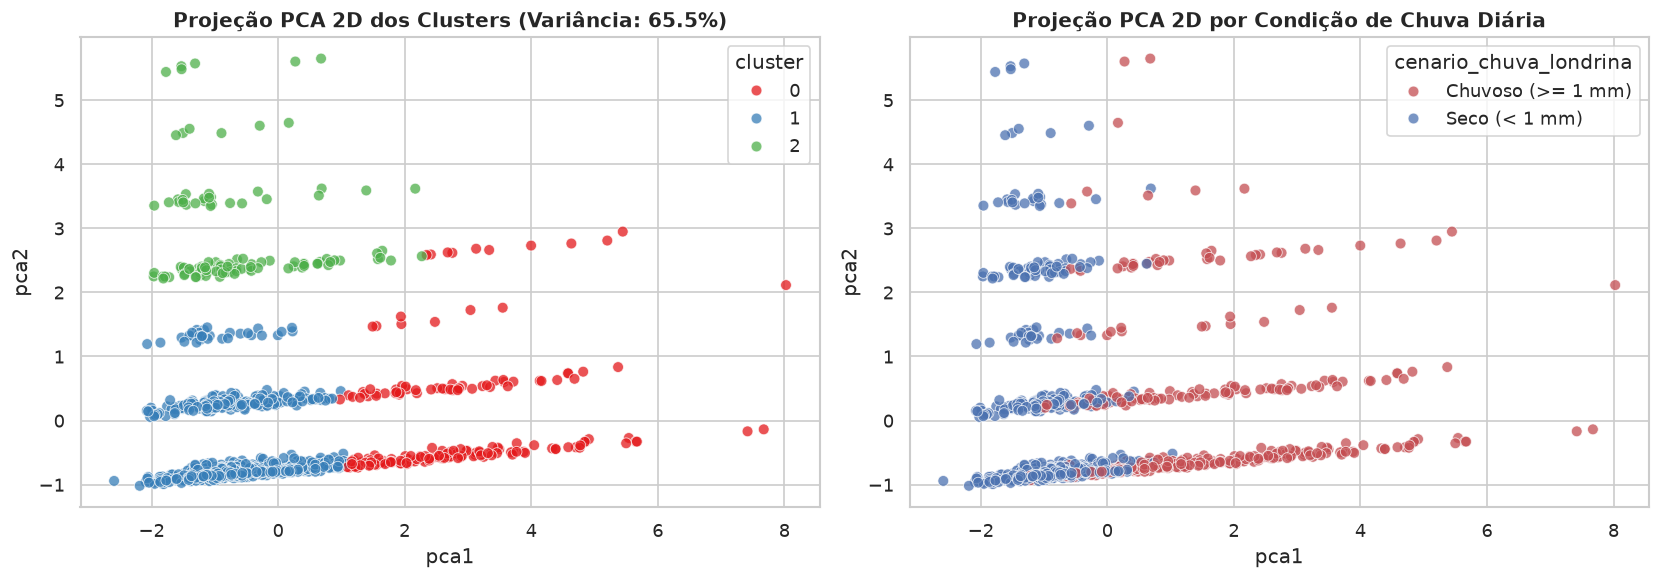

,temp_media_c,amplitude_termica_c,precip_londrina_mm,era5_londrina_horas_chuva,total_acidentes,acidentes_graves_ou_fatais
cluster,,,,,,
0,21.92,5.82,15.56,14.40,0.37,0.05
1,22.54,11.20,0.94,1.91,0.34,0.00
2,22.53,10.73,1.84,2.55,1.42,1.02


In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, silhouette_score

def bootstrap_ci(y_true, y_prob, metric_fn, n_boot=500, seed=42):
    rng = np.random.default_rng(seed)
    scores = []
    y_t, y_p = np.asarray(y_true), np.asarray(y_prob)
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_t), len(y_t))
        if len(np.unique(y_t[idx])) < 2:
            continue
        scores.append(metric_fn(y_t[idx], y_p[idx]))
    return np.percentile(scores, [2.5, 97.5])

# 1. Classificação Supervisionada de Severidade por Ocorrência (Alvo: Ferido Grave ou Óbito)
prf_ml = prf_full.sort_values(['data', 'horario']).reset_index(drop=True)
prf_ml['hora_num'] = pd.to_numeric(prf_ml['horario'].astype(str).str.slice(0, 2), errors='coerce').fillna(12)
prf_ml['fim_de_semana'] = prf_ml['data'].dt.day_of_week.isin([5, 6]).astype(int)

occ_num = ['km', 'veiculos', 'hora_num', 'temp_media_c', 'amplitude_termica_c', 'precip_londrina_mm', 'fim_de_semana']
occ_nom = ['tipo_acidente', 'fase_dia', 'tipo_pista', 'tracado_via', 'uso_solo', 'condicao_metereologica']

train_occ = prf_ml[prf_ml['ano_arquivo'].isin([2022, 2023])].copy()
val_occ = prf_ml[prf_ml['ano_arquivo'] == 2024].copy()
test_occ = prf_ml[prf_ml['ano_arquivo'] == 2025].copy()

prep_occ = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), occ_num),
    ('nom', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('oh', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), occ_nom),
])

models = {
    'Naive Baseline': DummyClassifier(strategy='prior', random_state=42),
    'Logistic Regression (L2)': LogisticRegression(C=0.5, class_weight='balanced', random_state=42, max_iter=500),
    'Random Forest (Reg.)': RandomForestClassifier(n_estimators=200, max_depth=4, min_samples_leaf=15, class_weight='balanced', random_state=42),
    'Gradient Boosting (Reg.)': GradientBoostingClassifier(n_estimators=100, learning_rate=0.03, max_depth=2, min_samples_leaf=20, random_state=42),
}

results = []
for name, clf in models.items():
    pipe = Pipeline([('prep', prep_occ), ('clf', clf)])
    pipe.fit(train_occ[occ_num + occ_nom], train_occ['tem_grave_ou_morte'])
    v_prob = pipe.predict_proba(val_occ[occ_num + occ_nom])[:, 1]
    t_prob = pipe.predict_proba(test_occ[occ_num + occ_nom])[:, 1]
    ci_v = bootstrap_ci(val_occ['tem_grave_ou_morte'], v_prob, roc_auc_score)
    results.append({
        'Modelo': name,
        'Val ROC-AUC (2024)': round(roc_auc_score(val_occ['tem_grave_ou_morte'], v_prob), 3),
        'Val ROC-AUC IC 95%': f'[{ci_v[0]:.3f}, {ci_v[1]:.3f}]',
        'Val PR-AUC (2024)': round(average_precision_score(val_occ['tem_grave_ou_morte'], v_prob), 3),
        'Val F1 (2024)': round(f1_score(val_occ['tem_grave_ou_morte'], (v_prob >= 0.45).astype(int)), 3),
        'Test ROC-AUC (2025)': round(roc_auc_score(test_occ['tem_grave_ou_morte'], t_prob), 3),
        'Test PR-AUC (2025)': round(average_precision_score(test_occ['tem_grave_ou_morte'], t_prob), 3),
        'Test F1 (2025)': round(f1_score(test_occ['tem_grave_ou_morte'], (t_prob >= 0.45).astype(int)), 3),
    })

print('=== CLASSIFICAÇÃO DE SEVERIDADE (Alvo: Ferido Grave ou Óbito) ===')
display(pd.DataFrame(results))

# 2. Clusterização K-Means dos Dias Climático-Viários (2022-2024)
clust_cols = ['temp_media_c', 'amplitude_termica_c', 'precip_londrina_mm', 'era5_londrina_horas_chuva', 'total_acidentes', 'acidentes_graves_ou_fatais']
X_c = StandardScaler().fit_transform(daily_22_24[clust_cols].fillna(0))
for k in range(2, 7):
    score = silhouette_score(X_c, KMeans(n_clusters=k, random_state=42, n_init=20).fit_predict(X_c))
    print(f'k={k} -> Silhouette Score = {score:.4f}')

km3 = KMeans(n_clusters=3, random_state=42, n_init=20)
clust_vis = daily_22_24.copy()
clust_vis['cluster'] = km3.fit_predict(X_c)
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_c)
clust_vis['pca1'], clust_vis['pca2'] = coords[:, 0], coords[:, 1]

fig_ml, axes_ml = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=clust_vis, x='pca1', y='pca2', hue='cluster', palette='Set1', alpha=0.75, s=42, ax=axes_ml[0])
axes_ml[0].set_title(f'Projeção PCA 2D dos Clusters (Variância: {pca.explained_variance_ratio_.sum()*100:.1f}%)', fontweight='bold')
sns.scatterplot(data=clust_vis, x='pca1', y='pca2', hue='cenario_chuva_londrina', palette={'Seco (< 1 mm)': '#4C72B0', 'Chuvoso (>= 1 mm)': '#C44E52'}, alpha=0.75, s=42, ax=axes_ml[1])
axes_ml[1].set_title('Projeção PCA 2D por Condição de Chuva Diária', fontweight='bold')
plt.tight_layout()
plt.show()
display(clust_vis.groupby('cluster')[clust_cols].mean().round(2))

### Avaliação dos Modelos Supervisionados e da Clusterização

* **Classificação de Severidade (`tem_grave_ou_morte`):** A **Regressão Logística regularizada (L2)** superou todos os modelos em árvore e o baseline ingênuo na validação de 2024 (`ROC-AUC = 0,563`, IC 95% `[0,450, 0,668]`, `PR-AUC = 0,276`, `F1 = 0,364`) e no teste cego de 2025 (`ROC-AUC = 0,584`, `PR-AUC = 0,357`, `F1 = 0,448`), demonstrando maior robustez contra *overfitting* em séries com cerca de ~340 sinistros no conjunto de treino.
* **Clusterização K-Means:** O pico de *Silhouette Score* ($0{,}4040$) ocorre em **$k = 3$**, separando nitidamente os dias chuvosos ($15{,}56\text{ mm/dia}$, baixíssima taxa de graves $0{,}05/\text{dia}$), os dias secos rotineiros ($n = 772$ dias sem ocorrências graves) e os dias críticos de alta severidade ($n = 119$ dias com média de $1{,}42$ sinistros/dia e $1{,}02$ graves/fatais).

## 7. Síntese Executiva

### Q&A

* **Pergunta Principal — Como a frequência diária e a gravidade dos sinistros variam segundo o clima em Londrina (2022–2024)?**  
  Nos $1.096$ dias do recorte oficial ($509$ sinistros, $99{,}4\%$ na BR-369), dias chuvosos ($\ge 1\text{ mm}$) apresentam contagem bruta diária menor ($0{,}430$ vs. $0{,}485/\text{dia}$), mas reduzem a letalidade viária pela metade ($1{,}68\%$ vs. $3{,}64\%$, chegando a **$0{,}00\%$ de óbitos** durante os $41$ sinistros sob chuva/garoa).
* **Pergunta Secundária 1 — Dias chuvosos vs. secos:** $0{,}430/\text{dia}$ vs. $0{,}485/\text{dia}$ ($p = 0{,}1675$). No nível modal, motocicletas caem $-19{,}5\%$, enquanto caminhões sobem $+17{,}7\%$ (2022–2024) e $+27{,}0\%$ (2022–2025).
* **Pergunta Secundária 2 — Faixas de temperatura:** Dias frios ($\le 19^\circ\text{C}$) concentram a maior frequência diária ($0{,}527/\text{dia}$).
* **Pergunta Secundária 3 — Severidade e letalidade:** Hipótese confirmada na letalidade ($0{,}00\%$ sob chuva na PRF vs. $3{,}21\%$ em tempo seco/nublado).
* **Pergunta Secundária 4 — Concordância PRF vs. INMET:** $100{,}0\%$ ($> 0\text{ mm}$) e $95{,}1\%$ ($\ge 1\text{ mm}$) na estação local de Londrina (`83766` + complemento).

### Data Analysis Key Findings

* **Paradoxo explicado pelo registro horário (`6,93%` das horas com chuva):** Como apenas $1.786$ de $25.767$ horas medidas no INMET `A835` têm chuva e o fluxo de motos recua sob tempo chuvoso, a contagem de 24 horas não sobe na chuva — exceto entre caminhões ($+17{,}7\%$) e aos sábados chuvosos ($54{,}9/100\text{d}$ vs. $47{,}2/100\text{d}$ secos).
* **Picos horários distintos por transporte:** Moto e Carro concentram sinistros nos horários de pico urbano (`07h–08h` e `17h–18h`), enquanto caminhões atingem seu pico matinal às `08h`.
* **Assimetria estrutural de papéis por gênero:** Homens somam $84{,}5\%$ dos condutores envolvidos ($98{,}9\%$ em caminhões e $100\%$ em ônibus), e mulheres somam $60{,}1\%$ dos passageiros, com maior retração feminina ao volante em dias chuvosos ($-20{,}9\%$).

### Insights or Next Steps

* **Consolidar o Relatório Analítico Final em `reports/`:** Reunir todas as tabelas, gráficos (`fig01` a `fig05`), interpretações críticas e limitações (ausência de VMD horário e de denominador por gênero) quando for o momento da entrega analítica final.